# Bloques, inspección y depuración: modelos que se pueden mantener

El mariposario quiere sumar clases a la app: primero insectos y animales pequeños, después quién sabe qué. Cada cambio significa tocar el modelo: agregar un bloque convolucional, meter una capa de normalización, cambiar el tamaño de la capa final. En `02-entrenamiento/01_una_cnn_para_la_naturaleza` la red tenía tres bloques convolucionales escritos uno por uno. Este notebook trata lo que pasa cuando hay que cambiarla.

Los videos *Modular Architectures* y *Model Inspecting and Debugging* del curso plantean dos ideas. La primera: escribir cada capa a mano funciona, pero cada cambio obliga a tocar dos lugares (`__init__` y `forward`), y es fácil equivocarse sin que salte ningún error. La segunda: un modelo se puede inspeccionar por dentro, y esa inspección es la forma de encontrar los errores. Aquí las llevamos a código:

- escribimos la CNN de tres bloques capa por capa y reproducimos dos bugs que trae esa forma de escribir, uno de ellos sin ningún mensaje de error;
- armamos herramientas que detectan esos bugs de forma automática;
- refactorizamos la red con `nn.Sequential` y con un bloque propio, y comprobamos que las tres versiones calculan **exactamente** lo mismo;
- inspeccionamos el modelo con `print`, `parameters`, `named_parameters`, `children` y `modules`;
- depuramos el error de formas que aparece al agregar un cuarto bloque;
- revisamos con estadísticas cómo quedan los pesos y las activaciones recién creada la red.

`01-modelos/01_nn_module` del módulo 2 ya explicó `__init__` y `forward`, `super().__init__()`, `ModuleList`, los hooks, cómo leer un error de formas y cómo contar parámetros. Aquí lo damos por sabido y lo usamos sobre una red más grande.

El notebook tarda uno o dos minutos en una CPU; la parte más lenta es un entrenamiento corto de la sección 3.

**Contenido**

1. Preparación
2. La CNN escrita a mano
3. Un bloque que se declara y nunca se usa
4. Cómo detectar capas sin usar
5. Un nombre repetido
6. Primer refactor: `nn.Sequential`
7. Segundo refactor: un bloque propio
8. La misma red, tres veces
9. Cambiar una línea
10. `Sequential` dentro de un `forward` propio
11. Inspeccionar: `print`, `parameters` y `named_parameters`
12. `children` contra `modules`
13. Depurar un error de formas
14. Inspeccionar la inicialización
15. Resumen y ejercicios

## 1. Preparación

Usamos el subconjunto de CIFAR-100 del módulo: 15 clases de tres superclases (flores, insectos y mamíferos pequeños), con 500 imágenes de entrenamiento por clase. Las precargamos en memoria como tensores normalizados con la media y la desviación de cada canal. Para casi todo el notebook basta un lote de 64 imágenes: lo que importa es la estructura del modelo, no entrenarlo.

In [1]:
import time

import numpy as np
import torch
from torch import nn
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"       # modulo-4/data

CLASES = ["orchid", "poppy", "rose", "sunflower", "tulip",              # flores
          "bee", "beetle", "butterfly", "caterpillar", "cockroach",     # insectos
          "hamster", "mouse", "rabbit", "shrew", "squirrel"]            # mamíferos pequeños

cifar = datasets.CIFAR100(root=RAIZ, train=True, download=True)
indice_original = [cifar.classes.index(nombre) for nombre in CLASES]
etiquetas_originales = torch.tensor(cifar.targets)
mascara = torch.isin(etiquetas_originales, torch.tensor(indice_original))

imagenes = torch.tensor(cifar.data[mascara.numpy()]).permute(0, 3, 1, 2).float() / 255     # [N, 3, 32, 32]
nueva_etiqueta = {original: nueva for nueva, original in enumerate(indice_original)}
etiquetas = torch.tensor([nueva_etiqueta[int(e)] for e in etiquetas_originales[mascara]])
del cifar                                                                               # libera los 50.000

media = imagenes.mean(dim=(0, 2, 3), keepdim=True)
desviacion = imagenes.std(dim=(0, 2, 3), keepdim=True)
X = (imagenes - media) / desviacion

x = X[:64]                    # el lote con el que miramos formas y salidas
print("imágenes:", tuple(X.shape), "  etiquetas:", tuple(etiquetas.shape), "  clases:", len(etiquetas.unique()))
print("media por canal      :", media.flatten().numpy().round(3))
print("desviación por canal :", desviacion.flatten().numpy().round(3))

Versión de PyTorch: 2.11.0+cpu


imágenes: (7500, 3, 32, 32)   etiquetas: (7500,)   clases: 15
media por canal      : [0.531 0.475 0.383]
desviación por canal : [0.269 0.253 0.27 ]


## 2. La CNN escrita a mano

La red de `02-entrenamiento/01_una_cnn_para_la_naturaleza`: tres bloques convolución → ReLU → max pooling, en que los canales crecen y el tamaño se reduce a la mitad, seguidos de un clasificador.

| Paso | Forma de la salida |
|---|---|
| entrada | `[lote, 3, 32, 32]` |
| bloque 1: `Conv2d(3, 32)` → ReLU → `MaxPool2d(2)` | `[lote, 32, 16, 16]` |
| bloque 2: `Conv2d(32, 64)` → ReLU → `MaxPool2d(2)` | `[lote, 64, 8, 8]` |
| bloque 3: `Conv2d(64, 128)` → ReLU → `MaxPool2d(2)` | `[lote, 128, 4, 4]` |
| `Flatten` | `[lote, 2048]` |
| `Linear(2048, 512)` → ReLU → `Dropout(0.5)` | `[lote, 512]` |
| `Linear(512, 15)` | `[lote, 15]` |

Las convoluciones usan kernel 3 con relleno 1, así que mantienen el alto y el ancho; solo el pooling los reduce. El 2048 de la capa lineal sale de multiplicar lo que queda después del tercer bloque: 128 canales × 4 × 4.

Escrita capa por capa, como se escribe la primera vez:

In [2]:
class CNNExplicita(nn.Module):
    def __init__(self, n_clases=15):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2)
        self.aplanar = nn.Flatten()
        self.fc1 = nn.Linear(128 * 4 * 4, 512)
        self.relu4 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, n_clases)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))     # [lote, 32, 16, 16]
        x = self.pool2(self.relu2(self.conv2(x)))     # [lote, 64, 8, 8]
        x = self.pool3(self.relu3(self.conv3(x)))     # [lote, 128, 4, 4]
        x = self.aplanar(x)                           # [lote, 2048]
        x = self.dropout(self.relu4(self.fc1(x)))     # [lote, 512]
        return self.fc2(x)                            # [lote, 15]


def contar(modelo):
    return sum(p.numel() for p in modelo.parameters())


def miles(n):
    return f"{n:,}".replace(",", ".")          # 1150031 -> "1.150.031"


torch.manual_seed(0)
explicita = CNNExplicita()
print("salida:", tuple(explicita(x).shape), "  parámetros:", miles(contar(explicita)))

salida: (64, 15)   parámetros: 1.150.031


Funciona. Pero mira cómo está escrita: los tres bloques son nueve líneas casi iguales en `__init__`, que solo cambian en los números de canales, y otras tres líneas casi iguales en `forward`. Cada capa existe en dos lugares, y nada obliga a que esos dos lugares estén de acuerdo. Las dos secciones siguientes muestran qué pasa cuando no lo están.

## 3. Un bloque que se declara y nunca se usa

El mariposario trae más clases y alguien decide que la red necesita un cuarto bloque, de 128 a 256 canales. Agrega las tres capas en `__init__`... y se olvida de `forward`. Lo escribimos como una subclase que solo agrega esas tres líneas; `forward` se hereda sin cambios:

In [3]:
class CNNConCuartoBloque(CNNExplicita):
    def __init__(self, n_clases=15):
        super().__init__(n_clases)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)     # declaradas...
        self.relu4b = nn.ReLU()
        self.pool4 = nn.MaxPool2d(2)                                    # ...pero forward no las llama


torch.manual_seed(0)
olvidada = CNNConCuartoBloque()
print("salida:", tuple(olvidada(x).shape))
print("parámetros con el cuarto bloque:", miles(contar(olvidada)),
      "  sin él:", miles(contar(explicita)),
      "  diferencia:", miles(contar(olvidada) - contar(explicita)))
print("¿conv4 aparece en print(modelo)?", "conv4" in str(olvidada))

salida: (64, 15)
parámetros con el cuarto bloque: 1.445.199   sin él: 1.150.031   diferencia: 295.168
¿conv4 aparece en print(modelo)? True


Ningún error. La salida tiene la forma correcta, porque `forward` sigue siendo el de tres bloques y la capa lineal sigue recibiendo 2048 números. El modelo tiene 295.168 parámetros más, `print` muestra `conv4`, y quien mire por encima creerá que la red tiene cuatro bloques.

¿Y al entrenar? Hacemos 60 pasos con Adam sobre lotes de 64 y guardamos una copia de los pesos de `conv4` antes de empezar:

In [4]:
def entrenar_pasos(modelo, pasos=60, lote=64, lr=1e-3, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()
    modelo.train()
    perdidas = []
    for _ in range(pasos):
        indices = torch.randint(len(X), (lote,), generator=generador)
        optimizador.zero_grad()
        perdida = criterio(modelo(X[indices]), etiquetas[indices])
        perdida.backward()
        optimizador.step()
        perdidas.append(perdida.item())
    return optimizador, perdidas


conv4_antes = olvidada.conv4.weight.detach().clone()
fc1_antes = olvidada.fc1.weight.detach().clone()
inicio = time.perf_counter()
optimizador, perdidas = entrenar_pasos(olvidada)

print(f"pérdida: primeros 10 pasos {np.mean(perdidas[:10]):.3f}   últimos 10 pasos {np.mean(perdidas[-10:]):.3f}"
      f"   ({time.perf_counter() - inicio:.0f} s)")
print("¿el optimizador recibió los pesos de conv4?",
      any(p is olvidada.conv4.weight for grupo in optimizador.param_groups for p in grupo["params"]))
print("gradiente de conv4.weight:", olvidada.conv4.weight.grad)
print("¿conv4 cambió?", not torch.equal(conv4_antes, olvidada.conv4.weight))
print("¿fc1 cambió?  ", not torch.equal(fc1_antes, olvidada.fc1.weight))

pérdida: primeros 10 pasos 2.675   últimos 10 pasos 2.126   (65 s)
¿el optimizador recibió los pesos de conv4? True
gradiente de conv4.weight: None
¿conv4 cambió? False
¿fc1 cambió?   True


La pérdida baja como en cualquier entrenamiento (con 15 clases parte cerca de $\ln 15 \approx 2.71$). El optimizador recibió los pesos de `conv4`, porque `parameters()` devuelve todo lo registrado en `__init__`, se use o no. Pero `conv4` nunca participó en un cálculo, así que `backward()` no le dejó gradiente: su `.grad` es `None`. Según la [documentación de `Optimizer.zero_grad`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html), los optimizadores de `torch.optim` se saltan por completo el paso de un parámetro cuyo gradiente es `None`, y en efecto `conv4` termina exactamente como empezó. `fc1`, que sí se usa, cambió.

El modelo entrenado es la red de tres bloques de siempre, con 295.168 parámetros de adorno. Que la pérdida baje no avisa nada: el bug no cambia lo que la red calcula, cambia lo que creemos que calcula. Es el problema que señala el video *Modular Architectures*: al agregar un bloque es fácil olvidar llamarlo en `forward`, y no salta ningún error.

## 4. Cómo detectar capas sin usar

La pista del gradiente sirve para detectarlo de forma automática. La misma documentación de `zero_grad` lo garantiza: si los gradientes se borran con `set_to_none=True` y después se hace un `backward()`, los parámetros que no recibieron gradiente quedan en `None`. Todo parámetro que participó en el cálculo tiene un gradiente, aunque valga cero.

In [5]:
def parametros_sin_gradiente(modelo, x, y):
    """Una pasada y un backward; devuelve los parámetros que quedaron sin gradiente."""
    modelo.zero_grad(set_to_none=True)
    nn.functional.cross_entropy(modelo(x), y).backward()
    sin_gradiente = [nombre for nombre, p in modelo.named_parameters() if p.requires_grad and p.grad is None]
    modelo.zero_grad(set_to_none=True)
    return sin_gradiente


y = etiquetas[:64]
print("red de tres bloques       :", parametros_sin_gradiente(explicita, x, y))
print("con el bloque olvidado    :", parametros_sin_gradiente(olvidada, x, y))

red de tres bloques       : []


con el bloque olvidado    : ['conv4.weight', 'conv4.bias']


Un detalle: la revisión tiene que ir después de `backward()` y antes del próximo `zero_grad()`. Con `set_to_none=True`, que es el valor por defecto según la [documentación de `Optimizer.zero_grad`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html), los gradientes no se ponen en cero sino en `None` ([`Module.zero_grad`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.zero_grad) hace lo mismo), y justo después de un `zero_grad()` todos los parámetros parecen "sin usar".

Esta revisión tiene un punto ciego: solo ve capas con parámetros. Si lo que se olvida en `forward` es una ReLU o un `Dropout`, no hay ningún gradiente que mirar. Para eso sirven los hooks de `01-modelos/01_nn_module` (sección 5): según la [documentación de `register_forward_hook`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook), el hook se ejecuta cada vez que `forward()` calcula una salida. Enganchamos uno que cuenta llamadas en cada capa "hoja" (las que no contienen otras capas), hacemos una pasada y vemos cuáles nunca se ejecutaron. Lo probamos también con un modelo que se olvida del `Dropout`:

In [6]:
def capas_sin_usar(modelo, x):
    """Una pasada con un hook en cada capa hoja; devuelve las capas que nunca se ejecutaron."""
    llamadas = {}
    ganchos = []
    for nombre, capa in modelo.named_modules():
        if len(list(capa.children())) == 0:               # capa hoja
            llamadas[nombre] = 0

            def contar_llamada(capa, entrada, salida, nombre=nombre):
                llamadas[nombre] += 1

            ganchos.append(capa.register_forward_hook(contar_llamada))
    with torch.no_grad():
        modelo(x)
    for gancho in ganchos:
        gancho.remove()
    return [nombre for nombre, veces in llamadas.items() if veces == 0]


class SinDropout(CNNExplicita):
    def forward(self, x):                                 # igual que el original, pero sin self.dropout
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        return self.fc2(self.relu4(self.fc1(self.aplanar(x))))


sin_dropout = SinDropout()
print("red de tres bloques     :", capas_sin_usar(explicita, x))
print("con el bloque olvidado  :", capas_sin_usar(olvidada, x))
print("sin dropout en forward  :", capas_sin_usar(sin_dropout, x))
print("   y la revisión de gradientes no lo ve:", parametros_sin_gradiente(sin_dropout, x, y))

red de tres bloques     : []


con el bloque olvidado  : ['conv4', 'relu4b', 'pool4']


sin dropout en forward  : ['dropout']


   y la revisión de gradientes no lo ve: []


La revisión con hooks encuentra las tres capas del bloque olvidado, incluidas la ReLU y el pooling, que no tienen parámetros, y encuentra el `Dropout` olvidado, que la revisión de gradientes no ve. Ese bug es peor de lo que parece: el modelo entrena sin la regularización que creemos que tiene.

Las dos funciones toman un lote y menos de un segundo. Vale la pena correrlas una vez cada vez que se cambia la arquitectura, antes de lanzar un entrenamiento largo.

## 5. Un nombre repetido

El segundo bug de escribir capa por capa sale de copiar y pegar. Para el cuarto bloque alguien copia las tres líneas del tercero y cambia los canales, pero se olvida de cambiar el nombre:

In [7]:
class NombreRepetido(CNNExplicita):
    def __init__(self, n_clases=15):
        super().__init__(n_clases)
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)     # debía llamarse conv4
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2)


repetido = NombreRepetido()
print("parámetros:", miles(contar(repetido)), f"  (la red de tres bloques tiene {miles(contar(explicita))})")
print("convoluciones registradas:", [(nombre, tuple(capa.weight.shape)) for nombre, capa in repetido.named_children()
                                     if isinstance(capa, nn.Conv2d)])
try:
    repetido(x)
except RuntimeError as error:
    print("\nRuntimeError:", error)

parámetros: 1.371.343   (la red de tres bloques tiene 1.150.031)
convoluciones registradas: [('conv1', (32, 3, 3, 3)), ('conv2', (64, 32, 3, 3)), ('conv3', (256, 128, 3, 3))]



RuntimeError: Given groups=1, weight of size [256, 128, 3, 3], expected input[64, 64, 8, 8] to have 128 channels, but got 64 channels instead


Python no avisa cuando se asigna dos veces el mismo atributo: el segundo `self.conv3` **reemplaza** al primero. La convolución de 64 a 128 canales desapareció del modelo (no está entre las registradas), y en su lugar quedó una de 128 a 256. La red tiene ahora *más* parámetros que antes, pero menos capas de las que creemos.

Esta vez sí hay error, en `forward`, y el mensaje se entiende si se lee con cuidado: unos pesos de forma `[256, 128, 3, 3]` esperaban una entrada de 128 canales y recibieron una de 64. Pero señala a la línea `self.conv3(x)` de `forward`, que está bien escrita; el error está en `__init__`. Con nombres numerados a mano, cada bloque nuevo obliga a inventar nombres (`relu4` ya estaba ocupado por el clasificador, así que arriba tuvimos que llamar `relu4b` a la del cuarto bloque) y cada nombre es una oportunidad de chocar con otro.

La salida a los dos bugs es la misma: que cada capa se escriba en un solo lugar.

## 6. Primer refactor: `nn.Sequential`

`nn.Sequential` guarda las capas en el orden en que se le pasan y, según su [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html), su `forward()` le pasa la entrada a la primera y "encadena" la salida de cada una con la entrada de la siguiente. Las capas se declaran una vez y el orden de `forward` queda implícito en el orden de la lista. Agrupamos la red en dos partes, las características (`caracteristicas`) y el clasificador (`clasificador`):

In [8]:
class CNNSecuencial(nn.Module):
    def __init__(self, n_clases=15):
        super().__init__()
        self.caracteristicas = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, n_clases),
        )

    def forward(self, x):
        return self.clasificador(self.caracteristicas(x))


secuencial = CNNSecuencial()
print(secuencial)

CNNSecuencial(
  (caracteristicas): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (clasificador): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=15, bias=True)
  )
)


`forward` pasó de seis líneas a una, y ya no se puede olvidar una capa en `forward` porque `forward` no nombra capas. Las capas ya no tienen nombres propios sino posiciones: la tercera convolución es `caracteristicas[6]`. Por eso tampoco hay nombres que choquen.

Queda una repetición: las tres líneas de `caracteristicas` siguen siendo la misma idea escrita tres veces con distintos números.

## 7. Segundo refactor: un bloque propio

Un bloque convolución → ReLU → pooling es una pieza que se repite, así que la escribimos como un módulo propio que recibe los canales de entrada y de salida:

In [9]:
class BloqueConv(nn.Module):
    """Conv 3×3 (mantiene el tamaño) → ReLU → MaxPool 2×2 (lo reduce a la mitad)."""

    def __init__(self, canales_entrada, canales_salida):
        super().__init__()
        self.bloque = nn.Sequential(
            nn.Conv2d(canales_entrada, canales_salida, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        return self.bloque(x)


class CNNModular(nn.Module):
    def __init__(self, n_clases=15, canales=(32, 64, 128), lado=32):
        super().__init__()
        entradas = (3,) + tuple(canales[:-1])
        self.caracteristicas = nn.Sequential(*[BloqueConv(a, b) for a, b in zip(entradas, canales)])
        lado_final = lado // 2 ** len(canales)                       # cada bloque divide el lado por 2
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(canales[-1] * lado_final * lado_final, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, n_clases),
        )

    def forward(self, x):
        return self.clasificador(self.caracteristicas(x))


modular = CNNModular()
print(modular.caracteristicas)
print("\nsalida:", tuple(modular(x).shape), "  parámetros:", miles(contar(modular)))

Sequential(
  (0): BloqueConv(
    (bloque): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (1): BloqueConv(
    (bloque): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (2): BloqueConv(
    (bloque): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
)

salida: (64, 15)   parámetros: 1.150.031


Ahora la arquitectura se describe con una tupla: `canales=(32, 64, 128)` son tres bloques con esos canales de salida, y el tamaño de la capa lineal se calcula a partir de ella (32 → 16 → 8 → 4 con tres bloques). Agregar un bloque es agregar un número a la tupla.

El video *Modular Architectures* recomienda este orden de trabajo: empezar explícito, aunque se repita, y refactorizar una vez que funciona. Refactorizar quiere decir cambiar la forma del código **sin** cambiar lo que hace. La sección siguiente lo comprueba.

## 8. La misma red, tres veces

Las tres versiones tienen el mismo número de parámetros, pero se guardan con nombres distintos. `state_dict()` es, según su [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.state_dict), un diccionario con todo el estado del módulo, cuyas claves son los nombres de los parámetros y *buffers*. Ponemos las claves lado a lado:

In [10]:
claves = {nombre: list(modelo.state_dict().keys())
          for nombre, modelo in [("explícita", explicita), ("Sequential", secuencial), ("bloques", modular)]}

print(f"{'explícita':12s} {'Sequential':26s} {'bloques':36s} forma")
for k_exp, k_seq, k_mod in zip(*claves.values()):
    forma = tuple(explicita.state_dict()[k_exp].shape)
    print(f"{k_exp:12s} {k_seq:26s} {k_mod:36s} {forma}")

explícita    Sequential                 bloques                              forma
conv1.weight caracteristicas.0.weight   caracteristicas.0.bloque.0.weight    (32, 3, 3, 3)
conv1.bias   caracteristicas.0.bias     caracteristicas.0.bloque.0.bias      (32,)
conv2.weight caracteristicas.3.weight   caracteristicas.1.bloque.0.weight    (64, 32, 3, 3)
conv2.bias   caracteristicas.3.bias     caracteristicas.1.bloque.0.bias      (64,)
conv3.weight caracteristicas.6.weight   caracteristicas.2.bloque.0.weight    (128, 64, 3, 3)
conv3.bias   caracteristicas.6.bias     caracteristicas.2.bloque.0.bias      (128,)
fc1.weight   clasificador.1.weight      clasificador.1.weight                (512, 2048)
fc1.bias     clasificador.1.bias        clasificador.1.bias                  (512,)
fc2.weight   clasificador.4.weight      clasificador.4.weight                (15, 512)
fc2.bias     clasificador.4.bias        clasificador.4.bias                  (15,)


Diez tensores en las tres, en el mismo orden y con las mismas formas. Los nombres cuentan dónde vive cada parámetro: `conv1.weight` es un atributo directo; `caracteristicas.0.weight` es la posición 0 del `Sequential`; `caracteristicas.0.bloque.0.weight` es la convolución dentro del `Sequential` de un `BloqueConv`, que a su vez es la posición 0 del `Sequential` de características. Faltan las posiciones 1, 2, 4, 5... porque las ReLU, los poolings, `Flatten` y `Dropout` no tienen parámetros.

Por eso no se puede cargar directamente el estado de una versión en otra. `load_state_dict` revisa por defecto que las claves coincidan (su argumento `strict`, según la [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.load_state_dict), obliga a que coincidan exactamente):

In [11]:
try:
    modular.load_state_dict(explicita.state_dict())
except RuntimeError as error:
    print("RuntimeError:", str(error)[:300], "...")

RuntimeError: Error(s) in loading state_dict for CNNModular:
	Missing key(s) in state_dict: "caracteristicas.0.bloque.0.weight", "caracteristicas.0.bloque.0.bias", "caracteristicas.1.bloque.0.weight", "caracteristicas.1.bloque.0.bias", "caracteristicas.2.bloque.0.weight", "caracteristicas.2.bloque.0.bias", "clasi ...


Como el orden y las formas coinciden, basta con renombrar: tomar los valores de la versión explícita en orden y ponerles las claves de la otra versión. Después comparamos las salidas con `torch.equal`, que exige que sean idénticas bit a bit. Los tres modelos van en modo evaluación para que el `Dropout` no apague valores distintos en cada uno:

In [12]:
def copiar_por_orden(origen, destino):
    valores = list(origen.state_dict().values())
    claves_destino = list(destino.state_dict().keys())
    assert all(v.shape == destino.state_dict()[k].shape for k, v in zip(claves_destino, valores))
    destino.load_state_dict(dict(zip(claves_destino, valores)))


copiar_por_orden(explicita, secuencial)
copiar_por_orden(explicita, modular)

for modelo in [explicita, secuencial, modular]:
    modelo.eval()
with torch.no_grad():
    salida_explicita, salida_secuencial, salida_modular = explicita(x), secuencial(x), modular(x)

print("¿Sequential da exactamente lo mismo que la explícita?", torch.equal(salida_explicita, salida_secuencial))
print("¿Los bloques dan exactamente lo mismo?               ", torch.equal(salida_explicita, salida_modular))

¿Sequential da exactamente lo mismo que la explícita? True
¿Los bloques dan exactamente lo mismo?                True


Idénticas. Las tres clases son tres formas de escribir la misma función: las mismas operaciones, en el mismo orden, con los mismos pesos. Esta comprobación es la red de seguridad de un refactor. Si un refactor cambia el orden de dos capas o se salta una, la comparación falla (ejercicio 4).

## 9. Cambiar una línea

La ganancia de la versión modular aparece al cambiar la arquitectura. El video *Modular Architectures* pone de ejemplo agregar normalización por lotes (`BatchNorm2d`) a todos los bloques: en la versión explícita serían tres capas nuevas en `__init__`, tres llamadas nuevas en `forward` y tres nombres nuevos. En la modular es una línea, dentro de `BloqueConv`. Aquí no entramos en qué hace `BatchNorm2d` ni por qué ayuda a entrenar; solo la usamos como ejemplo de cambio:

In [13]:
class BloqueConvNormalizado(BloqueConv):
    def __init__(self, canales_entrada, canales_salida):
        super().__init__(canales_entrada, canales_salida)
        self.bloque = nn.Sequential(
            nn.Conv2d(canales_entrada, canales_salida, kernel_size=3, padding=1),
            nn.BatchNorm2d(canales_salida),                   # la línea nueva
            nn.ReLU(),
            nn.MaxPool2d(2),
        )


normalizada = CNNModular()
normalizada.caracteristicas = nn.Sequential(*[BloqueConvNormalizado(a, b) for a, b in [(3, 32), (32, 64), (64, 128)]])

print("salida:", tuple(normalizada(x).shape))
print("parámetros:", miles(contar(normalizada)), "  antes:", miles(contar(modular)),
      "  diferencia:", contar(normalizada) - contar(modular))
nuevas = [k for k in normalizada.state_dict() if k not in modular.state_dict()]
print(f"\nclaves nuevas en state_dict ({len(nuevas)}):")
for k in nuevas[:5]:
    print("  ", k, tuple(normalizada.state_dict()[k].shape))
print("   ...")

salida: (64, 15)
parámetros: 1.150.479   antes: 1.150.031   diferencia: 448

claves nuevas en state_dict (15):
   caracteristicas.0.bloque.1.weight (32,)
   caracteristicas.0.bloque.1.bias (32,)
   caracteristicas.0.bloque.1.running_mean (32,)
   caracteristicas.0.bloque.1.running_var (32,)
   caracteristicas.0.bloque.1.num_batches_tracked ()
   ...


Cada `BatchNorm2d` agrega dos parámetros entrenables por canal (una escala y un desplazamiento): 2 × (32 + 64 + 128) = 448. Pero `state_dict` creció en más claves que esas: aparecen `running_mean`, `running_var` y `num_batches_tracked`. No son parámetros, porque el optimizador no los toca; son *buffers*, estado que la capa actualiza por su cuenta. La documentación de `state_dict` lo dice: incluye parámetros y *buffers* persistentes, "por ejemplo, promedios móviles". Por eso al guardar un modelo se guarda `state_dict()` y no solo los parámetros.

El otro cambio típico, agregar un cuarto bloque, también es una línea: `canales=(32, 64, 128, 256)`. Con `CNNModular` funciona sin más, porque el tamaño de la capa lineal se calcula desde la tupla. Cuando ese tamaño está escrito a mano se rompe, y depurar ese error es el tema de la sección 13.

## 10. `Sequential` dentro de un `forward` propio

`Sequential` encadena capas en fila. Cuando el modelo tiene ramas o varias salidas, se combinan las dos herramientas: `Sequential` para los tramos en fila y un `forward` propio para el resto. Por ejemplo, una red que predice la clase (15) y también la superclase (flor, insecto o mamífero), con las mismas características para las dos:

In [14]:
class CNNDosSalidas(nn.Module):
    def __init__(self, canales=(32, 64, 128)):
        super().__init__()
        entradas = (3,) + tuple(canales[:-1])
        self.caracteristicas = nn.Sequential(*[BloqueConv(a, b) for a, b in zip(entradas, canales)])
        self.aplanar = nn.Flatten()
        self.cabeza_clase = nn.Linear(canales[-1] * 4 * 4, 15)
        self.cabeza_superclase = nn.Linear(canales[-1] * 4 * 4, 3)

    def forward(self, x, devolver_mapas=False):
        mapas = []
        for bloque in self.caracteristicas:            # un Sequential se puede recorrer como una lista
            x = bloque(x)
            mapas.append(x)
        z = self.aplanar(x)
        salidas = self.cabeza_clase(z), self.cabeza_superclase(z)
        return (*salidas, mapas) if devolver_mapas else salidas


dos_salidas = CNNDosSalidas()
logits_clase, logits_superclase, mapas = dos_salidas(x, devolver_mapas=True)
print("clase:", tuple(logits_clase.shape), "  superclase:", tuple(logits_superclase.shape))
print("mapas de cada bloque:", [tuple(m.shape) for m in mapas])

clase: (64, 15)   superclase: (64, 3)
mapas de cada bloque: [(64, 32, 16, 16), (64, 64, 8, 8), (64, 128, 4, 4)]


Un `Sequential` se puede recorrer con `for` y se puede indexar, así que `forward` puede usarlo entero (`self.caracteristicas(x)`) o bloque por bloque, por ejemplo para guardar los mapas de características de cada bloque y visualizarlos. La pérdida de este modelo sería la suma de dos entropías cruzadas, una por salida. Los `if` y las ramas que dependen de los datos se tratan en `03-grafos-dinamicos/01_grafos_dinamicos`.

## 11. Inspeccionar: `print`, `parameters` y `named_parameters`

El video *Model Inspecting and Debugging* repasa las herramientas para mirar un modelo por dentro. Las usamos sobre `modular`.

**`print(modelo)`** muestra el plano: los nombres, el tipo de cada capa y su configuración (canales, kernel, paso, relleno). No muestra cuántos parámetros hay, ni las formas de los datos que pasan, ni el orden en que `forward` usa las capas. Lo que muestra es el orden en que se **registraron** en `__init__`. Normalmente coinciden, pero nada lo garantiza:

In [15]:
class OrdenDistinto(nn.Module):
    def __init__(self):
        super().__init__()
        self.salida = nn.Linear(16, 2)            # se declara primero...
        self.entrada = nn.Linear(4, 16)

    def forward(self, x):
        return self.salida(torch.relu(self.entrada(x)))     # ...pero se usa al final


print(OrdenDistinto())

OrdenDistinto(
  (salida): Linear(in_features=16, out_features=2, bias=True)
  (entrada): Linear(in_features=4, out_features=16, bias=True)
)


`print` pone `salida` antes que `entrada`. Para conocer el orden real hay que leer `forward` o seguir una pasada con hooks, como en la sección 4.

**`parameters()`** no devuelve una lista sino un iterador ("Return an iterator over module parameters", dice su [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.parameters), que agrega que normalmente se le pasa a un optimizador). Un iterador se recorre una sola vez. Según el [glosario de Python](https://docs.python.org/3/glossary.html#term-iterator), una vez que se agota, cada llamada siguiente solo levanta `StopIteration` de nuevo. Eso produce un bug real:

In [16]:
parametros = modular.parameters()
print("¿Es una lista?", isinstance(parametros, list), " tipo:", type(parametros).__name__)
print("parámetros contados en la primera pasada:", sum(p.numel() for p in parametros))
print("parámetros contados en la segunda pasada:", sum(p.numel() for p in parametros))

try:
    torch.optim.Adam(parametros, lr=1e-3)
except ValueError as error:
    print("\nValueError:", error)

¿Es una lista? False  tipo: generator
parámetros contados en la primera pasada: 1150031
parámetros contados en la segunda pasada: 0

ValueError: optimizer got an empty parameter list


Guardar `modelo.parameters()` en una variable, usarla para contar y después dársela al optimizador falla: la segunda vez el iterador ya está vacío. Esta vez el optimizador avisa porque recibe una lista vacía (el mismo error que en `01-modelos/01_nn_module`, sección 4). La solución es llamar a `modelo.parameters()` cada vez, o guardar `list(modelo.parameters())`.

**Contar.** El total, los entrenables y cuántos hay en cada capa. Para ver los entrenables congelamos las características con `requires_grad_(False)`, que según la [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.requires_grad_) sirve para congelar parte de un modelo al reentrenarlo:

In [17]:
def contar_entrenables(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


print("total      :", f"{miles(contar(modular)):>10s}")
print("entrenables:", f"{miles(contar_entrenables(modular)):>10s}")
modular.caracteristicas.requires_grad_(False)
print("con las características congeladas, entrenables:", miles(contar_entrenables(modular)))
modular.caracteristicas.requires_grad_(True)

print(f"\n{'capa':34s} {'tipo':8s} {'parámetros':>11s} {'del total':>9s}")
for nombre, capa in modular.named_modules():
    propios = sum(p.numel() for p in capa.parameters(recurse=False))
    if propios:
        print(f"{nombre:34s} {type(capa).__name__:8s} {miles(propios):>11s} {propios / contar(modular):>9.1%}")

total      :  1.150.031
entrenables:  1.150.031
con las características congeladas, entrenables: 1.056.783

capa                               tipo      parámetros del total
caracteristicas.0.bloque.0         Conv2d           896      0.1%
caracteristicas.1.bloque.0         Conv2d        18.496      1.6%
caracteristicas.2.bloque.0         Conv2d        73.856      6.4%
clasificador.1                     Linear     1.049.088     91.2%
clasificador.4                     Linear         7.695      0.7%


De 1.150.031 parámetros, 1.049.088 (el 91.2%) están en la primera capa lineal, la que conecta los 2048 valores de las características con 512 neuronas. Las tres convoluciones juntas tienen menos de 100.000. Es lo mismo que pasaba en la red densa de MNIST (`01-modelos/01_nn_module`, sección 7): la capa densa que recibe la imagen, o lo que queda de ella, concentra casi todo. Las convoluciones son baratas porque reutilizan el mismo filtro en toda la imagen (`00-convoluciones/01_filtros_y_mapas_de_caracteristicas`).

**`named_parameters()`** da el nombre y la forma de cada tensor:

In [18]:
for nombre, parametro in modular.named_parameters():
    print(f"{nombre:40s} {str(tuple(parametro.shape)):18s} {miles(parametro.numel()):>9s}")

caracteristicas.0.bloque.0.weight        (32, 3, 3, 3)            864
caracteristicas.0.bloque.0.bias          (32,)                     32
caracteristicas.1.bloque.0.weight        (64, 32, 3, 3)        18.432
caracteristicas.1.bloque.0.bias          (64,)                     64
caracteristicas.2.bloque.0.weight        (128, 64, 3, 3)       73.728
caracteristicas.2.bloque.0.bias          (128,)                   128
clasificador.1.weight                    (512, 2048)        1.048.576
clasificador.1.bias                      (512,)                   512
clasificador.4.weight                    (15, 512)              7.680
clasificador.4.bias                      (15,)                     15


Dos formas de leer:

- Una convolución guarda sus pesos como `[salida, entrada, alto, ancho]`: `caracteristicas.1.bloque.0.weight` tiene forma `(64, 32, 3, 3)`, 64 filtros de 32 canales de 3 × 3 cada uno. Es la forma que da la [documentación de `Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).
- Una capa lineal guarda `[salida, entrada]`, al revés del orden en que se escriben sus argumentos: `Linear(2048, 512)` tiene pesos de forma `(512, 2048)`. Cada fila son los pesos de una neurona de salida. La [documentación de `Linear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html) escribe la operación como $y = xA^\top + b$, y el módulo 1 la dedujo en `04-matematica-de-pytorch/02_capas_y_activaciones`, sección 1. La comprobamos con la capa de verdad:

In [19]:
fc1 = modular.clasificador[1]
z = modular.clasificador[0](modular.caracteristicas(x))          # lo que recibe fc1: [64, 2048]
with torch.no_grad():
    print("forma de los pesos:", tuple(fc1.weight.shape), "  forma de la entrada:", tuple(z.shape))
    print("¿z @ W.T + b coincide con fc1(z)?", torch.allclose(z @ fc1.weight.T + fc1.bias, fc1(z), atol=1e-6))

forma de los pesos: (512, 2048)   forma de la entrada: (64, 2048)
¿z @ W.T + b coincide con fc1(z)? True


Esa forma es la clave para depurar errores de formas, en la sección 13: la **segunda** dimensión de los pesos de una capa lineal es lo que la capa espera recibir.

## 12. `children` contra `modules`

Dos formas de recorrer los submódulos, que el video compara con recorrer una carpeta: `children()` solo mira el primer nivel, como listar una carpeta; `modules()` entra en todas las subcarpetas. Según la [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.children), `children()` devuelve "immediate children modules" y `modules()` devuelve "all modules in the network". Los contamos en las tres versiones de la red:

In [20]:
for nombre, modelo in [("explícita", explicita), ("Sequential", secuencial), ("bloques", modular)]:
    print(f"{nombre:11s} children: {len(list(modelo.children())):2d}   modules: {len(list(modelo.modules())):2d}")

explícita   children: 14   modules: 15
Sequential  children:  2   modules: 17
bloques     children:  2   modules: 23


La versión explícita tiene sus 14 capas como hijos directos, y `modules()` devuelve esas 14 más el propio modelo: 15. La versión con `Sequential` tiene solo 2 hijos (`caracteristicas` y `clasificador`) y 17 módulos: el modelo, los dos `Sequential` y las mismas 14 capas. La de bloques también tiene 2 hijos, pero 23 módulos en total, porque cada uno de los tres `BloqueConv` agrega dos niveles: el bloque y el `Sequential` que tiene adentro. `named_modules()` da el nombre de cada uno; lo indentamos según la profundidad, que es el número de puntos del nombre:

In [21]:
for nombre, capa in modular.named_modules():
    profundidad = 0 if nombre == "" else nombre.count(".") + 1
    print("    " * profundidad + (nombre.split(".")[-1] or "(el modelo)"), "-", type(capa).__name__)

(el modelo) - CNNModular
    caracteristicas - Sequential
        0 - BloqueConv
            bloque - Sequential
                0 - Conv2d
                1 - ReLU
                2 - MaxPool2d
        1 - BloqueConv
            bloque - Sequential
                0 - Conv2d
                1 - ReLU
                2 - MaxPool2d
        2 - BloqueConv
            bloque - Sequential
                0 - Conv2d
                1 - ReLU
                2 - MaxPool2d
    clasificador - Sequential
        0 - Flatten
        1 - Linear
        2 - ReLU
        3 - Dropout
        4 - Linear


Es el árbol del modelo. `children()` solo habría devuelto las dos ramas del primer nivel. Para tareas que tienen que llegar a todas las capas de un tipo, como contar capas, revisar estadísticas o cambiar la inicialización, se usa `modules()` o `named_modules()`:

In [22]:
convoluciones = [nombre for nombre, capa in modular.named_modules() if isinstance(capa, nn.Conv2d)]
print("convoluciones encontradas:", convoluciones)
print("con children() se habrían encontrado:", [n for n, c in modular.named_children() if isinstance(c, nn.Conv2d)])

convoluciones encontradas: ['caracteristicas.0.bloque.0', 'caracteristicas.1.bloque.0', 'caracteristicas.2.bloque.0']
con children() se habrían encontrado: []


Con `children()` no se encuentra ninguna, porque las convoluciones están dos niveles más abajo. Es un error fácil: un código que "aplica la inicialización a todas las convoluciones" recorriendo `children()` funciona con la red explícita y no hace nada, sin avisar, con la red modular.

Un último detalle de `modules()`: devuelve cada módulo una sola vez aunque aparezca en varios lugares. La documentación usa el ejemplo `nn.Sequential(l, l)`, la misma capa dos veces:

In [23]:
l = nn.Linear(2, 2)
dos_veces = nn.Sequential(l, l)
print("modules():", len(list(dos_veces.modules())), "  parameters():", len(list(dos_veces.parameters())))

llamadas = []
gancho = l.register_forward_hook(lambda capa, entrada, salida: llamadas.append(1))
dos_veces(torch.randn(1, 2))
gancho.remove()
print("veces que se ejecutó l en una pasada:", len(llamadas))

modules(): 2   parameters(): 2
veces que se ejecutó l en una pasada: 2


El `Sequential` y una sola `l` (2 módulos, 2 tensores de parámetros), aunque `l` se ejecuta dos veces en cada pasada. Es la forma correcta de **compartir** pesos entre dos lugares de la red. Hay que tenerlo en cuenta al contar: el número de capas que devuelve `modules()` no es el número de capas que se ejecutan.

## 13. Depurar un error de formas

Ahora el cambio de la sección 9, pero en una red donde el tamaño de la capa lineal está escrito a mano, como en casi todos los ejemplos: un cuarto bloque de 256 canales y la capa lineal que sigue esperando 128 × 4 × 4 = 2048.

In [24]:
class CuatroBloques(nn.Module):
    def __init__(self):
        super().__init__()
        self.caracteristicas = nn.Sequential(BloqueConv(3, 32), BloqueConv(32, 64), BloqueConv(64, 128),
                                             BloqueConv(128, 256))           # el bloque nuevo
        self.clasificador = nn.Sequential(nn.Flatten(), nn.Linear(2048, 512), nn.ReLU(), nn.Dropout(0.5),
                                          nn.Linear(512, 15))                 # sin cambios

    def forward(self, x):
        return self.clasificador(self.caracteristicas(x))


cuatro = CuatroBloques()
try:
    cuatro(x)
except RuntimeError as error:
    print("RuntimeError:", error)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x1024 and 2048x512)


El mensaje se lee como en `01-modelos/01_nn_module`, sección 6: `mat1` es la entrada (64 filas de 1024 valores) y `mat2` son los pesos traspuestos (2048 × 512). Para multiplicarlas, cada fila de la entrada tendría que traer 2048 valores, y trae 1024. El video *Model Inspecting and Debugging* propone un procedimiento en tres pasos.

**1. Qué espera la capa.** La segunda dimensión de sus pesos:

In [25]:
print("pesos de la primera capa lineal:", tuple(cuatro.clasificador[1].weight.shape), " -> espera", cuatro.clasificador[1].weight.shape[1], "valores")

pesos de la primera capa lineal: (512, 2048)  -> espera 2048 valores


**2. Qué recibe.** La forma más directa es poner un `print(x.shape)` en `forward`, después de las características y después de aplanar. Sin tocar la clase se puede hacer lo mismo con un *pre-hook*, que según la [documentación de `register_forward_pre_hook`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_pre_hook) se ejecuta antes de cada `forward()`. A diferencia del hook de la sección 4, alcanza a ejecutarse aunque el `forward` de la capa falle:

In [26]:
def mostrar_entrada(capa, entrada):
    print(f"   {type(capa).__name__:8s} recibe {tuple(entrada[0].shape)}")


ganchos = [cuatro.clasificador[0].register_forward_pre_hook(mostrar_entrada),      # Flatten
           cuatro.clasificador[1].register_forward_pre_hook(mostrar_entrada)]      # Linear
try:
    cuatro(x)
except RuntimeError:
    print("   (y falla)")
for gancho in ganchos:
    gancho.remove()

   Flatten  recibe (64, 256, 2, 2)
   Linear   recibe (64, 1024)
   (y falla)


**3. Comparar y corregir.** El aplanado recibe `[64, 256, 2, 2]`: el cuarto pooling dejó 2 × 2, y 256 × 2 × 2 = 1024. La capa espera 2048. La corrección es `nn.Linear(256 * 2 * 2, 512)`.

Mejor que hacer la cuenta a mano cada vez es dejar que la red la haga: una **pasada de prueba** con una imagen falsa del tamaño correcto, sin gradientes, dice cuántos valores salen de las características:

In [27]:
def tamano_aplanado(caracteristicas, forma_entrada=(3, 32, 32)):
    with torch.no_grad():
        return caracteristicas(torch.zeros(1, *forma_entrada)).numel()


for canales in [(32, 64, 128), (32, 64, 128, 256), (16, 32), (32, 64, 128, 256, 512)]:
    entradas = (3,) + canales[:-1]
    caracteristicas = nn.Sequential(*[BloqueConv(a, b) for a, b in zip(entradas, canales)])
    print(f"canales {str(canales):26s} -> la capa lineal debe recibir {tamano_aplanado(caracteristicas):5d}")

canales (32, 64, 128)              -> la capa lineal debe recibir  2048


canales (32, 64, 128, 256)         -> la capa lineal debe recibir  1024


canales (16, 32)                   -> la capa lineal debe recibir  2048


canales (32, 64, 128, 256, 512)    -> la capa lineal debe recibir   512


Con cinco bloques, 32 → 16 → 8 → 4 → 2 → 1: queda un solo valor por canal, 512 en total. Un sexto bloque ya no tendría qué reducir.

PyTorch tiene una alternativa que hace esa pasada por nosotros: [`nn.LazyLinear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html), una capa lineal que deduce `in_features` de la última dimensión de la primera entrada que recibe. Hasta esa primera llamada sus pesos son `UninitializedParameter`, y después se convierte en un `nn.Linear` normal:

In [28]:
torch.manual_seed(0)
perezosa = nn.Sequential(
    nn.Sequential(BloqueConv(3, 32), BloqueConv(32, 64), BloqueConv(64, 128), BloqueConv(128, 256)),
    nn.Flatten(),
    nn.LazyLinear(512), nn.ReLU(), nn.Dropout(0.5), nn.Linear(512, 15),
)
print("antes de la primera pasada:", perezosa[2])
try:
    contar(perezosa)
except ValueError as error:
    print("contar parámetros -> ValueError:", str(error)[:95], "...")

perezosa(x)                                       # la pasada de prueba
print("después                   :", perezosa[2], "  parámetros:", miles(contar(perezosa)))

antes de la primera pasada: LazyLinear(in_features=0, out_features=512, bias=True)
contar parámetros -> ValueError: Attempted to use an uninitialized parameter in <method 'numel' of 'torch._C.TensorBase' objects ...


después                   : Linear(in_features=1024, out_features=512, bias=True)   parámetros: 920.911


Antes de la primera pasada la capa dice `in_features=0`, y ni siquiera se pueden contar los parámetros. Después es un `Linear(1024, 512)`.

La [documentación de los módulos perezosos](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.lazy.LazyModuleMixin.html) advierte que son una función experimental, que la red debe hacer una pasada de prueba antes de usarse (y, en su ejemplo, antes de crear el optimizador), y que el orden en que se inicializan los parámetros cambia, porque los módulos perezosos se inicializan después que todos los demás. Eso último se puede ver: con la misma semilla, la versión perezosa y la versión con el tamaño calculado tienen las mismas convoluciones, pero no las mismas capas lineales:

In [29]:
torch.manual_seed(0)
calculada = nn.Sequential(
    nn.Sequential(BloqueConv(3, 32), BloqueConv(32, 64), BloqueConv(64, 128), BloqueConv(128, 256)),
    nn.Flatten(),
    nn.Linear(1024, 512), nn.ReLU(), nn.Dropout(0.5), nn.Linear(512, 15),
)
print("¿mismas convoluciones?      ", all(torch.equal(a.weight, b.weight) for a, b in zip(
    [c for c in perezosa.modules() if isinstance(c, nn.Conv2d)], [c for c in calculada.modules() if isinstance(c, nn.Conv2d)])))
print("¿misma primera capa lineal? ", torch.equal(perezosa[2].weight, calculada[2].weight))
print("¿misma última capa lineal?  ", torch.equal(perezosa[5].weight, calculada[5].weight))

¿mismas convoluciones?       True
¿misma primera capa lineal?  False
¿misma última capa lineal?   False


En la red calculada, la primera capa lineal se inicializa al construirla, antes que la última. En la perezosa, la última se inicializa al construirla y la primera recién en la pasada de prueba, así que se reparten los números aleatorios en otro orden. Las dos redes son igual de válidas, pero un experimento que cambia `Linear` por `LazyLinear` no se puede comparar peso a peso con el original aunque use la misma semilla.

## 14. Inspeccionar la inicialización

El laboratorio de depuración del curso termina mirando con estadísticas los pesos de una red recién creada, sobre Fashion-MNIST. Lo hacemos con la CNN del video *CNNs Part 2* para imágenes de 28 × 28 en escala de grises: dos bloques (1 → 32 → 64 canales, 28 → 14 → 7) y un clasificador de `64 * 7 * 7` entradas.

La inicialización por defecto de PyTorch es la misma para las capas lineales y las convolucionales: según la documentación de [`Linear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html) y de [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), los pesos se sortean de una uniforme $\mathcal{U}(-\sqrt{k}, \sqrt{k})$ con $k = 1/\text{fan\_in}$, donde $\text{fan\_in}$ es el número de entradas de cada neurona: `in_features` en una lineal, y canales de entrada × alto × ancho del kernel en una convolución. Una uniforme en $(-a, a)$ tiene desviación $a/\sqrt{3}$ (`04-matematica-de-pytorch/02_capas_y_activaciones` del módulo 1, sección 2). Comparamos la predicción con lo que sale:

In [30]:
moda = datasets.FashionMNIST(root=RAIZ, train=True, download=True)
imagenes_moda = moda.data[:512].float().unsqueeze(1) / 255                          # [512, 1, 28, 28]
media_moda = (moda.data.float() / 255).mean()
desviacion_moda = (moda.data.float() / 255).std()
x_moda = (imagenes_moda - media_moda) / desviacion_moda
y_moda = moda.targets[:512]


def cnn_moda():
    return nn.Sequential(
        BloqueConv(1, 32), BloqueConv(32, 64),
        nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
    )


torch.manual_seed(0)
red_moda = cnn_moda()

print(f"{'capa':22s} {'fan_in':>6s} {'límite √k':>10s} {'máx |w|':>9s} {'desv. teórica':>14s} {'desv. medida':>13s} {'media':>9s}")
for nombre, capa in red_moda.named_modules():
    if isinstance(capa, (nn.Conv2d, nn.Linear)):
        w = capa.weight.detach()
        fan_in = w[0].numel()                                    # entradas de una neurona
        limite = 1 / fan_in ** 0.5
        print(f"{nombre:22s} {fan_in:6d} {limite:10.4f} {w.abs().max():9.4f} {limite / 3 ** 0.5:14.4f} "
              f"{w.std():13.4f} {w.mean():9.4f}")

capa                   fan_in  límite √k   máx |w|  desv. teórica  desv. medida     media
0.bloque.0                  9     0.3333    0.3325         0.1925        0.1908   -0.0153
1.bloque.0                288     0.0589    0.0589         0.0340        0.0340    0.0003
3                        3136     0.0179    0.0179         0.0103        0.0103    0.0000
5                         128     0.0884    0.0884         0.0510        0.0514    0.0002


Las cuatro capas siguen la predicción: el peso más grande queda justo bajo el límite $\sqrt{k}$, y la desviación medida coincide con $\sqrt{k}/\sqrt{3}$ en las dos capas con más pesos y difiere en menos de 1% en las otras dos, que tienen pocos (288 y 1.280) y por eso más variación al azar. Las medias son cercanas a cero; la que más se aleja es la de la primera convolución, que promedia solo 288 pesos. `w[0].numel()` es el número de pesos de una neurona (o de un filtro), que es justo el `fan_in`: 9 en la primera convolución (1 canal × 3 × 3), 288 en la segunda (32 × 3 × 3). Por eso los pesos de la primera convolución son unas seis veces más grandes que los de la segunda: tienen menos entradas que sumar.

Los histogramas de cada capa, con el límite teórico marcado:

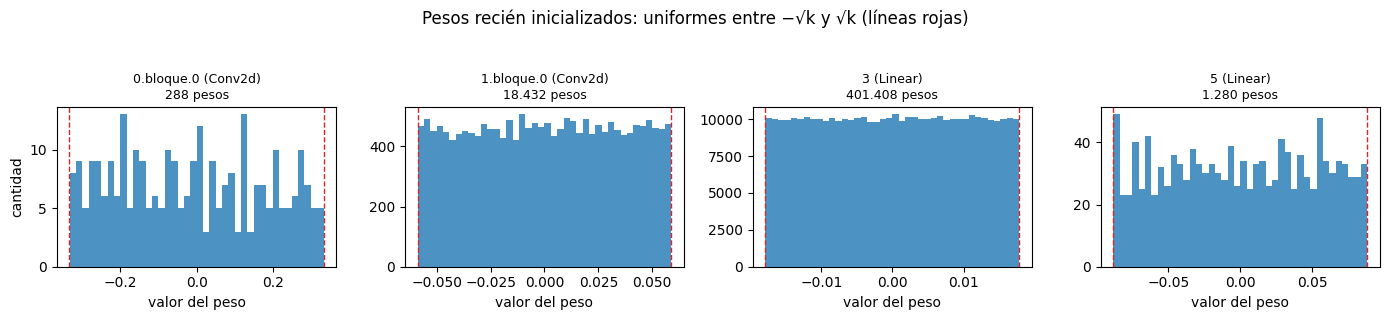

In [31]:
fig, ejes = plt.subplots(1, 4, figsize=(14, 3))
capas_con_pesos = [(n, c) for n, c in red_moda.named_modules() if isinstance(c, (nn.Conv2d, nn.Linear))]
for eje, (nombre, capa) in zip(ejes, capas_con_pesos):
    w = capa.weight.detach().flatten()
    limite = 1 / capa.weight[0].numel() ** 0.5
    eje.hist(w.numpy(), bins=40, color="tab:blue", alpha=0.8)
    eje.axvline(-limite, color="tab:red", linestyle="--", linewidth=1)
    eje.axvline(limite, color="tab:red", linestyle="--", linewidth=1)
    eje.set_title(f"{nombre} ({type(capa).__name__})\n{miles(w.numel())} pesos", fontsize=9)
    eje.set_xlabel("valor del peso")
ejes[0].set_ylabel("cantidad")
plt.suptitle("Pesos recién inicializados: uniformes entre −√k y √k (líneas rojas)", y=1.05)
plt.tight_layout()
plt.show()

Histogramas planos, cortados exactamente en las líneas rojas: uniformes. La primera convolución tiene solo 288 pesos, así que su histograma es más irregular, pero respeta el mismo límite.

Que los pesos sigan la fórmula no dice cómo se comportan los datos al atravesar la red. Para eso miramos las **activaciones**: con hooks en cada capa hoja, anotamos la desviación de la salida de cada una para un lote real de 512 imágenes. Lo comparamos con la inicialización de He (`nn.init.kaiming_normal_`), que el módulo 1 dedujo para capas seguidas de ReLU (sección 3 del mismo notebook) y que aplicamos solo a esas capas, como en `05-profundizacion/01_depurar_un_modelo` del módulo 2. Para encontrar las capas usamos `named_modules`, como en la sección 12:

In [32]:
def desviaciones_por_capa(red, x):
    resultados = []
    ganchos = [capa.register_forward_hook(
                   lambda capa, entrada, salida, nombre=nombre: resultados.append((nombre, type(capa).__name__, salida.std().item())))
               for nombre, capa in red.named_modules() if len(list(capa.children())) == 0]
    with torch.no_grad():
        salida = red(x)
    for gancho in ganchos:
        gancho.remove()
    return resultados, salida


def inicializar_he(red):
    capas = [c for c in red.modules() if isinstance(c, (nn.Conv2d, nn.Linear))]
    for capa in capas[:-1]:                         # todas menos la de salida, que no va seguida de ReLU
        nn.init.kaiming_normal_(capa.weight, nonlinearity="relu")
        nn.init.zeros_(capa.bias)
    return red


torch.manual_seed(0)
por_defecto, salida_defecto = desviaciones_por_capa(cnn_moda(), x_moda)
torch.manual_seed(0)
he, salida_he = desviaciones_por_capa(inicializar_he(cnn_moda()), x_moda)

print(f"desviación de la entrada: {x_moda.std():.3f}\n")
print(f"{'capa':22s} {'tipo':10s} {'por defecto':>12s} {'He':>8s}")
for (nombre, tipo, d1), (_, _, d2) in zip(por_defecto, he):
    print(f"{nombre:22s} {tipo:10s} {d1:12.4f} {d2:8.4f}")

criterio = nn.CrossEntropyLoss()
print(f"\npérdida inicial: por defecto {criterio(salida_defecto, y_moda):.3f}   He {criterio(salida_he, y_moda):.3f}"
      f"   (ln 10 = {np.log(10):.3f})")

desviación de la entrada: 0.999

capa                   tipo        por defecto       He
0.bloque.0             Conv2d           0.6062   1.4360
0.bloque.1             ReLU             0.3390   0.9611
0.bloque.2             MaxPool2d        0.3841   1.0956
1.bloque.0             Conv2d           0.2643   1.8774
1.bloque.1             ReLU             0.1575   1.0833
1.bloque.2             MaxPool2d        0.1873   1.2944
2                      Flatten          0.1873   1.2944
3                      Linear           0.1542   2.1355
4                      ReLU             0.0996   1.2719
5                      Linear           0.0619   0.7723

pérdida inicial: por defecto 2.305   He 2.580   (ln 10 = 2.303)


Con la inicialización por defecto, la desviación cae en cada capa con pesos: de 1 en la entrada a menos de 0.1 en la salida. Es lo que predijo el módulo 1 para pilas de capas lineales: con varianza $1/(3\,\text{fan\_in})$ cada capa seguida de ReLU achica las activaciones. Con He se mantienen del orden de 1 a lo largo de toda la red. Los poolings, de paso, suben la desviación, porque se quedan con el máximo de cada bloque de 2 × 2.

En una red de cuatro capas con pesos la diferencia no impide entrenar: con la inicialización por defecto, los logits salen chicos, las probabilidades casi parejas y la pérdida inicial queda muy cerca de $\ln 10$, lo esperable para 10 clases sin información. Con He la última capa recibe activaciones más grandes y la pérdida parte más alta. Ninguna de las dos es "la correcta" para todo: lo que esta inspección da es el diagnóstico. En una red profunda, una desviación que se encoge capa a capa es la señal de que los gradientes también se van a encoger, y vale la pena mirarla antes de entrenar.

## 15. Resumen

- Escribir cada capa a mano obliga a tocar `__init__` y `forward` en cada cambio. Un bloque declarado y no llamado en `forward` **no da error**: sus parámetros se cuentan y se le pasan al optimizador, pero nunca reciben gradiente y nunca cambian.
- Dos revisiones automáticas lo detectan: parámetros con `.grad` en `None` después de un `backward()`, y capas cuyo hook nunca se ejecutó en una pasada. Solo la segunda ve capas sin parámetros, como un `Dropout` olvidado.
- Asignar dos veces el mismo atributo reemplaza la capa sin avisar; el error aparece después, en `forward`, en una línea que está bien.
- `nn.Sequential` declara las capas una vez y encadena su `forward`. Un bloque propio (`BloqueConv`) evita repetir la misma estructura, y una tupla de canales describe la arquitectura.
- Un refactor se comprueba copiando los pesos (las claves de `state_dict` cambian con la estructura) y verificando con `torch.equal` que la salida es idéntica.
- `state_dict` incluye parámetros y *buffers*, como las medias móviles de `BatchNorm2d`.
- `print(modelo)` muestra el orden de registro, no el de `forward`. `parameters()` es un iterador que se agota. `named_parameters()` da nombres y formas: `Conv2d` guarda `[salida, entrada, alto, ancho]` y `Linear` guarda `[salida, entrada]`.
- `children()` recorre el primer nivel y `modules()` todo el árbol, devolviendo cada módulo una vez aunque se use varias.
- Para un error de formas: qué espera la capa (`weight.shape`), qué recibe (`print` o un *pre-hook*), comparar. Mejor aún, calcular el tamaño con una pasada de prueba, o usar `LazyLinear` sabiendo que cambia el orden de inicialización.
- La inicialización por defecto de `Linear` y `Conv2d` es uniforme en $\pm 1/\sqrt{\text{fan\_in}}$. Con ella las activaciones se achican capa a capa; con He se mantienen.

## Ejercicios

1. Antes de ejecutar: ¿cuántos parámetros tiene `CNNModular(canales=(32, 64, 128, 256))`? ¿Más o menos que la de tres bloques? Haz la cuenta capa por capa y compruébala. ¿Por qué agregar un bloque puede *reducir* el total?
2. Junta `parametros_sin_gradiente` y `capas_sin_usar` en una sola función `revisar_arquitectura(modelo, x, y)` que imprima un informe. Pruébala con un modelo que use la misma `nn.ReLU()` en tres lugares de `forward`. ¿La marca como usada? ¿Cuántas veces se ejecuta su hook?
3. Escribe `copiar_por_nombre(origen, destino)` que no dependa del orden de `state_dict`: recorre las capas con pesos de cada modelo con `named_modules()` y empareja la k-ésima de uno con la k-ésima del otro. ¿En qué caso daría un resultado distinto de `copiar_por_orden`?
4. Haz un "refactor" equivocado de `CNNSecuencial` que intercambie el orden de la ReLU y el pooling en el primer bloque. ¿Sigue dando `torch.equal` contra la explícita? Explica el resultado (pista: ¿conmutan el máximo y la ReLU?). Repite cambiando el orden de la convolución y la ReLU.
5. Congela `caracteristicas` con `requires_grad_(False)`, crea el optimizador solo con los parámetros entrenables (`filter(lambda p: p.requires_grad, ...)`), entrena 50 pasos con `entrenar_pasos` adaptada y comprueba que las convoluciones no cambiaron y el clasificador sí.
6. Repite la tabla de desviaciones de la sección 14 con una red de seis bloques sobre CIFAR (sin pooling en los últimos para no quedarte sin píxeles). ¿Qué pasa con la desviación al final con cada inicialización?
7. En la sección 14, aplica He también a la capa de salida. ¿Cuánto vale ahora la pérdida inicial? ¿Por qué conviene que una red recién creada tenga una pérdida inicial cercana a $\ln(\text{clases})$?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- Los videos *Modular Architectures* (la red escrita capa por capa, el bloque nuevo que se olvida llamar en `forward` sin que salte un error, los choques de nombres, `Sequential` y los bloques propios, `BatchNorm` en todos los bloques cambiando una línea, empezar explícito y refactorizar después) y *Model Inspecting and Debugging* (`print`, `parameters`, `named_parameters`, `children` contra `modules` como carpetas y subcarpetas, la forma `[salida, entrada]` de `Linear`, y los tres pasos para depurar un error de formas) del módulo 4 del curso, y su laboratorio *Model Debugging, Inspection, and Modularization* (estadísticas de la inicialización sobre Fashion-MNIST).
- **CIFAR-100**, [página de Alex Krizhevsky](https://www.cs.toronto.edu/~kriz/cifar.html): "There are 500 training images and 100 testing images per class. The 100 classes in the CIFAR-100 are grouped into 20 superclasses", y en la tabla de superclases, "flowers: orchids, poppies, roses, sunflowers, tulips", "insects: bee, beetle, butterfly, caterpillar, cockroach" y "small mammals: hamster, mouse, rabbit, shrew, squirrel".

**Documentación de PyTorch**

- [`torch.nn.Module`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html):
  - Clase: "Base class for all neural network modules" y "Modules can also contain other Modules, allowing them to be nested in a tree structure."
  - `children()`: "Return an iterator over immediate children modules."
  - `modules()`: "Return an iterator over all modules in the network", con la nota "Duplicate modules are returned only once by default. In the following example, l will be returned only once", y el ejemplo `net = nn.Sequential(l, l)`.
  - `named_modules()`: "Return an iterator over all modules in the network, yielding both the name of the module as well as the module itself."
  - `parameters()`: "Return an iterator over module parameters. This is typically passed to an optimizer."
  - `named_parameters()`: "Return an iterator over module parameters, yielding both the name of the parameter as well as the parameter itself."
  - `state_dict()`: "Return a dictionary containing references to the whole state of the module. Both parameters and persistent buffers (e.g. running averages) are included. Keys are corresponding parameter and buffer names."
  - `load_state_dict()`, argumento `strict`: "whether to strictly enforce that the keys in state_dict match the keys returned by this module’s state_dict() function."
  - `register_forward_hook()`: "The hook will be called every time after forward() has computed an output."
  - `register_forward_pre_hook()`: "The hook will be called every time before forward() is invoked."
  - `requires_grad_()`: "Change if autograd should record operations on parameters in this module" y "This method is helpful for freezing part of the module for finetuning or training parts of a model individually".
  - `zero_grad()`, argumento `set_to_none`: "instead of setting to zero, set the grads to None."
- [`torch.optim.Optimizer.zero_grad`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html), argumento `set_to_none` ("Default: True"): "If the user requests `zero_grad(set_to_none=True)` followed by a backward pass, `.grad`s are guaranteed to be None for params that did not receive a gradient" y "torch.optim optimizers have a different behavior if the gradient is 0 or None (in one case it does the step with a gradient of 0 and in the other it skips the step altogether)."
- [`torch.nn.Sequential`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html): "Modules will be added to it in the order they are passed in the constructor", "The forward() method of Sequential accepts any input and forwards it to the first module it contains. It then “chains” outputs to inputs sequentially for each subsequent module, finally returning the output of the last module."
- [`torch.nn.Linear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html): "Applies an affine linear transformation to the incoming data: $y = xA^T + b$"; `weight`: "the learnable weights of the module of shape (out_features, in_features). The values are initialized from $\mathcal{U}(-\sqrt{k}, \sqrt{k})$, where $k = \frac{1}{\text{in\_features}}$".
- [`torch.nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html): `weight`: "the learnable weights of the module of shape (out_channels, in_channels/groups, kernel_size[0], kernel_size[1]). The values of these weights are sampled from $\mathcal{U}(-\sqrt{k}, \sqrt{k})$ where $k = \frac{groups}{C_\text{in} * \prod_{i=0}^{1}\text{kernel\_size}[i]}$".
- [`torch.nn.LazyLinear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html): "A torch.nn.Linear module where in_features is inferred", "In this module, the weight and bias are of torch.nn.UninitializedParameter class. They will be initialized after the first call to forward is done and the module will become a regular torch.nn.Linear module" y "The in_features argument of the Linear is inferred from the input.shape[-1]."
- [`LazyModuleMixin`](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.lazy.LazyModuleMixin.html): "Lazy modules are an experimental new feature under active development, and their API is likely to change", "The lazy modules should then perform “dry runs” to initialize all the components in the module", el comentario de su ejemplo "attaches an optimizer, since parameters can now be used as usual", y "A final caveat when using lazy modules is that the order of initialization of a network’s parameters may change, since the lazy modules are always initialized after other modules."

**Documentación de Python**

- [Glosario, *iterator*](https://docs.python.org/3/glossary.html#term-iterator): "At this point, the iterator object is exhausted and any further calls to its `__next__()` method just raise StopIteration again" y "One notable exception is code which attempts multiple iteration passes."

**Lo que no viene de una fuente** son los números de este notebook (parámetros, pérdidas, desviaciones, conteos de módulos): todos salen de las celdas de código. También son nuestras las dos revisiones automáticas de la sección 4, el ejemplo del nombre repetido, la comparación de las tres versiones con `torch.equal` y la comprobación de que `LazyLinear` cambia la inicialización con la misma semilla.